In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)


💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 6.1 マウスカーソル (`Rendering Mouse Cursor & Desktop GUI`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/6/6.1_Rendering_Mouse_Cursor.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.10%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20UEFI%20GOP-orange.svg)
![Chapter](https://img.shields.io/badge/Chapter-6.1%20(osbook__day06a)-green.svg)

---

## 📖 節の概要と学習目標

第5章において、MikanOS は 8×16 ビットマップフォントの描画、分割コンパイル、Newlib の静的リンクによる `sprintf()`、25行×80列の文字バッファを持つ `Console` クラス、そしてカーネル用書式付き出力関数 `printk()` を手に入れました。これによって、画面上に任意の文字列や数値をスクロール表示できるようになり、OS の内部状態を視覚的に観測する強力なデバッグ基盤が確立されました。

しかし、第5章までの画面は依然として **「真っ白な画面の左上に文字が表示されるだけの CUI（*Character User Interface*）的環境」** に過ぎません。

本節（**第6章 6.1節 / `osbook_day06a`**）から、MikanOS は現代的なグラフィカル・オペレーティングシステム（**GUI: *Graphical User Interface***）への決定的な一歩を踏み出します。その第一歩として、本節では以下の理論と技術を完全修得します：

1. **幾何構造の抽象化**: 2次元空間の位置と大きさを統一的に表現する `Vector2D<T>` クラステンプレートの設計と C++ ゼロオーバーヘッド原則
2. **矩形描画アルゴリズム**: 外枠を描く `DrawRectangle()` と塗りつぶす `FillRectangle()` の走査線数理、角の重複排除最適化、および VRAM リニアアドレッシング
3. **デスクトップ UI レイアウト設計**: 画面領域分割（デスクトップ背景青・タスクバー黒・スタートボタン灰）とカラーパレットの構築
4. **スプライトとカラーキーイング**: アスキーアート配列 `mouse_cursor_shape[24][16]`（15×24 画素）によるマウスカーソルの表現、白黒反転による視認性向上（HCI 視覚人間工学）、および透過ピクセルによる背景保持


## 1. なぜ OS にマウスカーソルとデスクトップ環境が必要なのか？（動機と課題）

### 1.1 CUI から GUI へのパラダイムシフト
コンピュータの初期のオペレーティングシステム（Unix, MS-DOS 等）は、キーボードからのテキスト入力と端末画面への文字列出力のみを行う **CUI（*Character User Interface*）** が主流でした。CUI はリソース消費が極めて少なく実装もシンプルですが、ユーザーは膨大なコマンド名と引数の構文を記憶していなければシステムを操作できません。

これに対し、1970年代にゼロックスのパロアルト研究所（Xerox PARC）で開発され、Apple Macintosh や Windows、X Window System で普及した **GUI（*Graphical User Interface*）** は、**WIMP（*Window, Icon, Menu, Pointer*）** と呼ばれるメタファを導入しました。ユーザーは画面上の視覚的オブジェクトをポインティングデバイス（マウス）で「指し示し（Point）」、「選択・決定（Click）」することで、直感的にコンピュータを操作できるようになりました。

### 1.2 OS にとっての「マウスカーソル」の責務
マウスカーソル（*Mouse Cursor / Pointer*）は、GUI において **「ユーザーの物理的な手の位置を仮想スクリーン上に投影した唯一の代理人（アバター）」** です。
OS がマウスカーソルを画面に描画するためには、以下の技術的課題を解決しなければなりません：

1. **画面の多層化と背景の調和**: マウスカーソルは画面上のあらゆる場所を移動します。そのため、背景が青であっても、黒であっても、白であっても、カーソルを見失わないようなコントラスト設計が必要です。
2. **矩形領域の幾何計算**: デスクトップ背景、タスクバー、ウィンドウ、ボタンなどの UI 部品はすべて2次元平面上の「四角形（Rectangle）」として構成されます。これらの位置（$x, y$）と寸法（$w, h$）を効率的かつ型安全に扱う幾何データ構造が不可欠です。
3. **透過色（カラーキーイング）処理**: マウスカーソルは長方形の画像データ（15×24 ピクセル）として定義されますが、実際のカーソルは矢印の形状をしています。矢印以外の領域を透明として扱い、背後にある壁紙や文字を破壊せずに残す仕組みが必要です。

本節（`osbook_day06a`）では、まず **静的なグラフィックスとして「デスクトップ背景」と「マウスカーソル」を描画する** ことから始めます。続く 6.2〜6.4 節において、PCI バスの探索と USB 3.0 (xHCI) ホストコントローラのドライバを実装し、実際のマウスの物理的移動に応じてカーソルを動かす完全なイベント駆動パイプラインへと発展させていきます。


## 2. 幾何学構造の抽象化: `Vector2D<T>` クラステンプレートの設計とメモリ効率

### 2.1 関数の引数爆発と型の安全性
ピクセル描画やウィンドウ操作を行う際、座標を指定するために関数の引数に `(int x, int y, int width, int height)` を個別に並べる手法は、引数の数が増えて可読性を損なうだけでなく、**「位置（Position）」と「大きさ（Size）」を取り違えるバグ**（例: `Draw(width, height, x, y)` のように順序を間違えて渡してしまう）を引き起こしやすくなります。

MikanOS では、この問題を解決するために 2次元ベクトルを表すクラステンプレート `Vector2D<T>` を導入しました：

```cpp
template <typename T>
struct Vector2D {
  T x, y;
};
```

### 2.2 幾何学的二面性（位置とサイズ）の統一
`Vector2D<T>` は、幾何学における **「位置ベクトル（点のアドレス）」** と **「寸法（幅と高さの大きさ）」** の双方を統一的に表現できます：
- **位置（Position）**: `Vector2D<int> pos{ 200, 100 };`（原点 $(0, 0)$ からの相対座標 $(x, y)$）
- **大きさ（Size）**: `Vector2D<int> size{ 15, 24 };`（幅 $\Delta x = 15$、高さ $\Delta y = 24$）

2つの位置ベクトルの差は寸法ベクトルとなり、位置ベクトルに寸法ベクトルを加算すると新しい位置ベクトルが得られます：
$$\mathbf{pos}_{	ext{new}} = \mathbf{pos}_{	ext{base}} + \mathbf{size}$$

### 2.3 C++ ゼロオーバーヘッド原則（Zero-Overhead Principle）
Bjarne Stroustrup が提唱した C++ の中核思想である **ゼロオーバーヘッド原則（*Zero-Overhead Principle*）** は、**「使わないものにコストを支払わない」「手作業で書いた同等のアセンブリコードよりも無駄のない機械語を生成する」** というものです。

`Vector2D<T>` はまさにこの原則を完璧に体現しています：
1. **仮想関数テーブル（vtable）の不在**: 仮想関数（`virtual`）を一切持たないため、`_vptr`（仮想ポインタ: 8バイト）のオーバーヘッドが存在しません。
2. **パディング（Padding）の不在**: メンバ変数は `T x, y;` の同型2つのみであるため、構造体アライメントに伴う内部パディングが一切発生しません。
3. **メモリサイズの一致**: `sizeof(Vector2D<int>)` は厳密に `sizeof(int) * 2 = 8` バイトであり、レジスタ1本（x86-64 の 64ビット汎用レジスタ `RAX` 等）に完全に収まります。


In [2]:
from common import Vector2DSim, Vector2D

# 1. Vector2DSim のインスタンス化と演算検証
pos = Vector2DSim(200, 100)
size = Vector2DSim(15, 24)
endpoint = pos + size
diff = endpoint - pos

print(f"基準位置 (pos):       {pos.as_tuple()} (x={pos.x}, y={pos.y})")
print(f"カーソル寸法 (size):   {size.as_tuple()} (幅={size.x}, 高さ={size.y})")
print(f"終端位置 (endpoint):   {endpoint.as_tuple()} (x={endpoint.x}, y={endpoint.y})")
print(f"相対差分 (diff):       {diff.as_tuple()} (等価性検証: {diff == size})")

# 2. メモリサイズの検証
import ctypes
class CppVector2DInt(ctypes.Structure):
    _fields_ = [("x", ctypes.c_int32), ("y", ctypes.c_int32)]

print(f"\nC++ sizeof(Vector2D<int>): {ctypes.sizeof(CppVector2DInt)} bytes (64bitレジスタ1本分)")
assert ctypes.sizeof(CppVector2DInt) == 8, "Vector2D<int> must be exactly 8 bytes!"


基準位置 (pos):       (200, 100) (x=200, y=100)
カーソル寸法 (size):   (15, 24) (幅=15, 高さ=24)
終端位置 (endpoint):   (215, 124) (x=215, y=124)
相対差分 (diff):       (15, 24) (等価性検証: True)

C++ sizeof(Vector2D<int>): 8 bytes (64bitレジスタ1本分)


## 3. 矩形描画アルゴリズムの徹底解剖: `DrawRectangle()` と `FillRectangle()`

MikanOS のグラフィックスサブシステム（`kernel/graphics.cpp`）には、GUI 画面を構築するための 2 つの基本プリミティブ関数が配備されています。

### 3.1 外枠描画: `DrawRectangle()`
`DrawRectangle()` は、指定された位置 `pos` とサイズ `size` の長方形の **輪郭線（外枠）のみ** を描画します。

```cpp
void DrawRectangle(PixelWriter& writer, const Vector2D<int>& pos,
                   const Vector2D<int>& size, const PixelColor& c) {
  for (int dx = 0; dx < size.x; ++dx) {
    writer.Write(pos.x + dx, pos.y, c);
    writer.Write(pos.x + dx, pos.y + size.y - 1, c);
  }
  for (int dy = 1; dy < size.y - 1; ++dy) {
    writer.Write(pos.x, pos.y + dy, c);
    writer.Write(pos.x + size.x - 1, pos.y + dy, c);
  }
}
```

#### 角ピクセルの重複排除最適化
このアルゴリズムで特筆すべきは、垂直線の走査ループが `dy = 1` から始まり `dy < size.y - 1` で終わる点です：
- 最初の水平線走査（`dx = 0` 〜 `size.x - 1`）で、**四隅（Top-Left, Top-Right, Bottom-Left, Bottom-Right）** のピクセルはすでに描画されています。
- もし垂直線走査を `dy = 0` から `size.y` まで回してしまうと、四隅のピクセルが **2回書き込まれる（二重描画）** ことになります。
- メモリマップド I/O（MMIO）である VRAM へのアクセスは、CPU キャッシュを通らないアンキャッシャブル（UC）メモリとして設定されることが多く、無駄なバス書き込みは描画パフォーマンスの低下に直結します。MikanOS では `dy` の走査範囲を狭めることで、**全ピクセルを過不足なくちょうど1回だけ書き込む $O(W + H)$ アルゴリズム** を実現しています。

総描画ピクセル数 $N_{	ext{outline}}$ は以下の数理で導出されます：
$$N_{	ext{outline}} = 2 	imes 	ext{size.x} + 2 	imes (	ext{size.y} - 2) = 2(	ext{size.x} + 	ext{size.y}) - 4$$

### 3.2 塗りつぶし矩形描画: `FillRectangle()`
`FillRectangle()` は、長方形の **内部領域全体を指定色で均一に塗りつぶし** ます。

```cpp
void FillRectangle(PixelWriter& writer, const Vector2D<int>& pos,
                   const Vector2D<int>& size, const PixelColor& c) {
  for (int dy = 0; dy < size.y; ++dy) {
    for (int dx = 0; dx < size.x; ++dx) {
      writer.Write(pos.x + dx, pos.y + dy, c);
    }
  }
}
```

#### 行優先走査（Row-Major Scanline）と VRAM キャッシュ親和性
なぜ外側のループが `dy`（行）で、内側のループが `dx`（列）なのでしょうか？
UEFI GOP のリニアフレームバッファにおいて、画面上のピクセル $(x, y)$ の物理アドレスは次式で計算されます：
$$	ext{Addr}(x, y) = 	ext{BaseAddr} + 4 	imes (y 	imes 	ext{pixels\_per\_scan\_line} + x)$$

- 内側ループで `dx` をインクリメントすると、アクセスする VRAM アドレスは $+4$ バイトずつ **完全に連続してインクリメント** されます。
- これにより、CPU のライトコンバイン（WC: *Write Combining*）バッファ（64バイト）が効率的に満たされ、PCIe バスのバースト書き込みがトリガーされます。
- もし外側を `dx`、内側を `dy`（列優先走査）にしてしまうと、1ピクセル書き込むごとに $	ext{stride} 	imes 4$ バイト（数キロバイト）も離れたアドレスへジャンプすることになり、CPU のストアパイプラインが壊滅的に失速します。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:21615: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 6.01 生成完了: /home/student/Documents/GitHub/study-mikanos/6/result/fig6_01_vector2d_and_rectangle_rendering.png


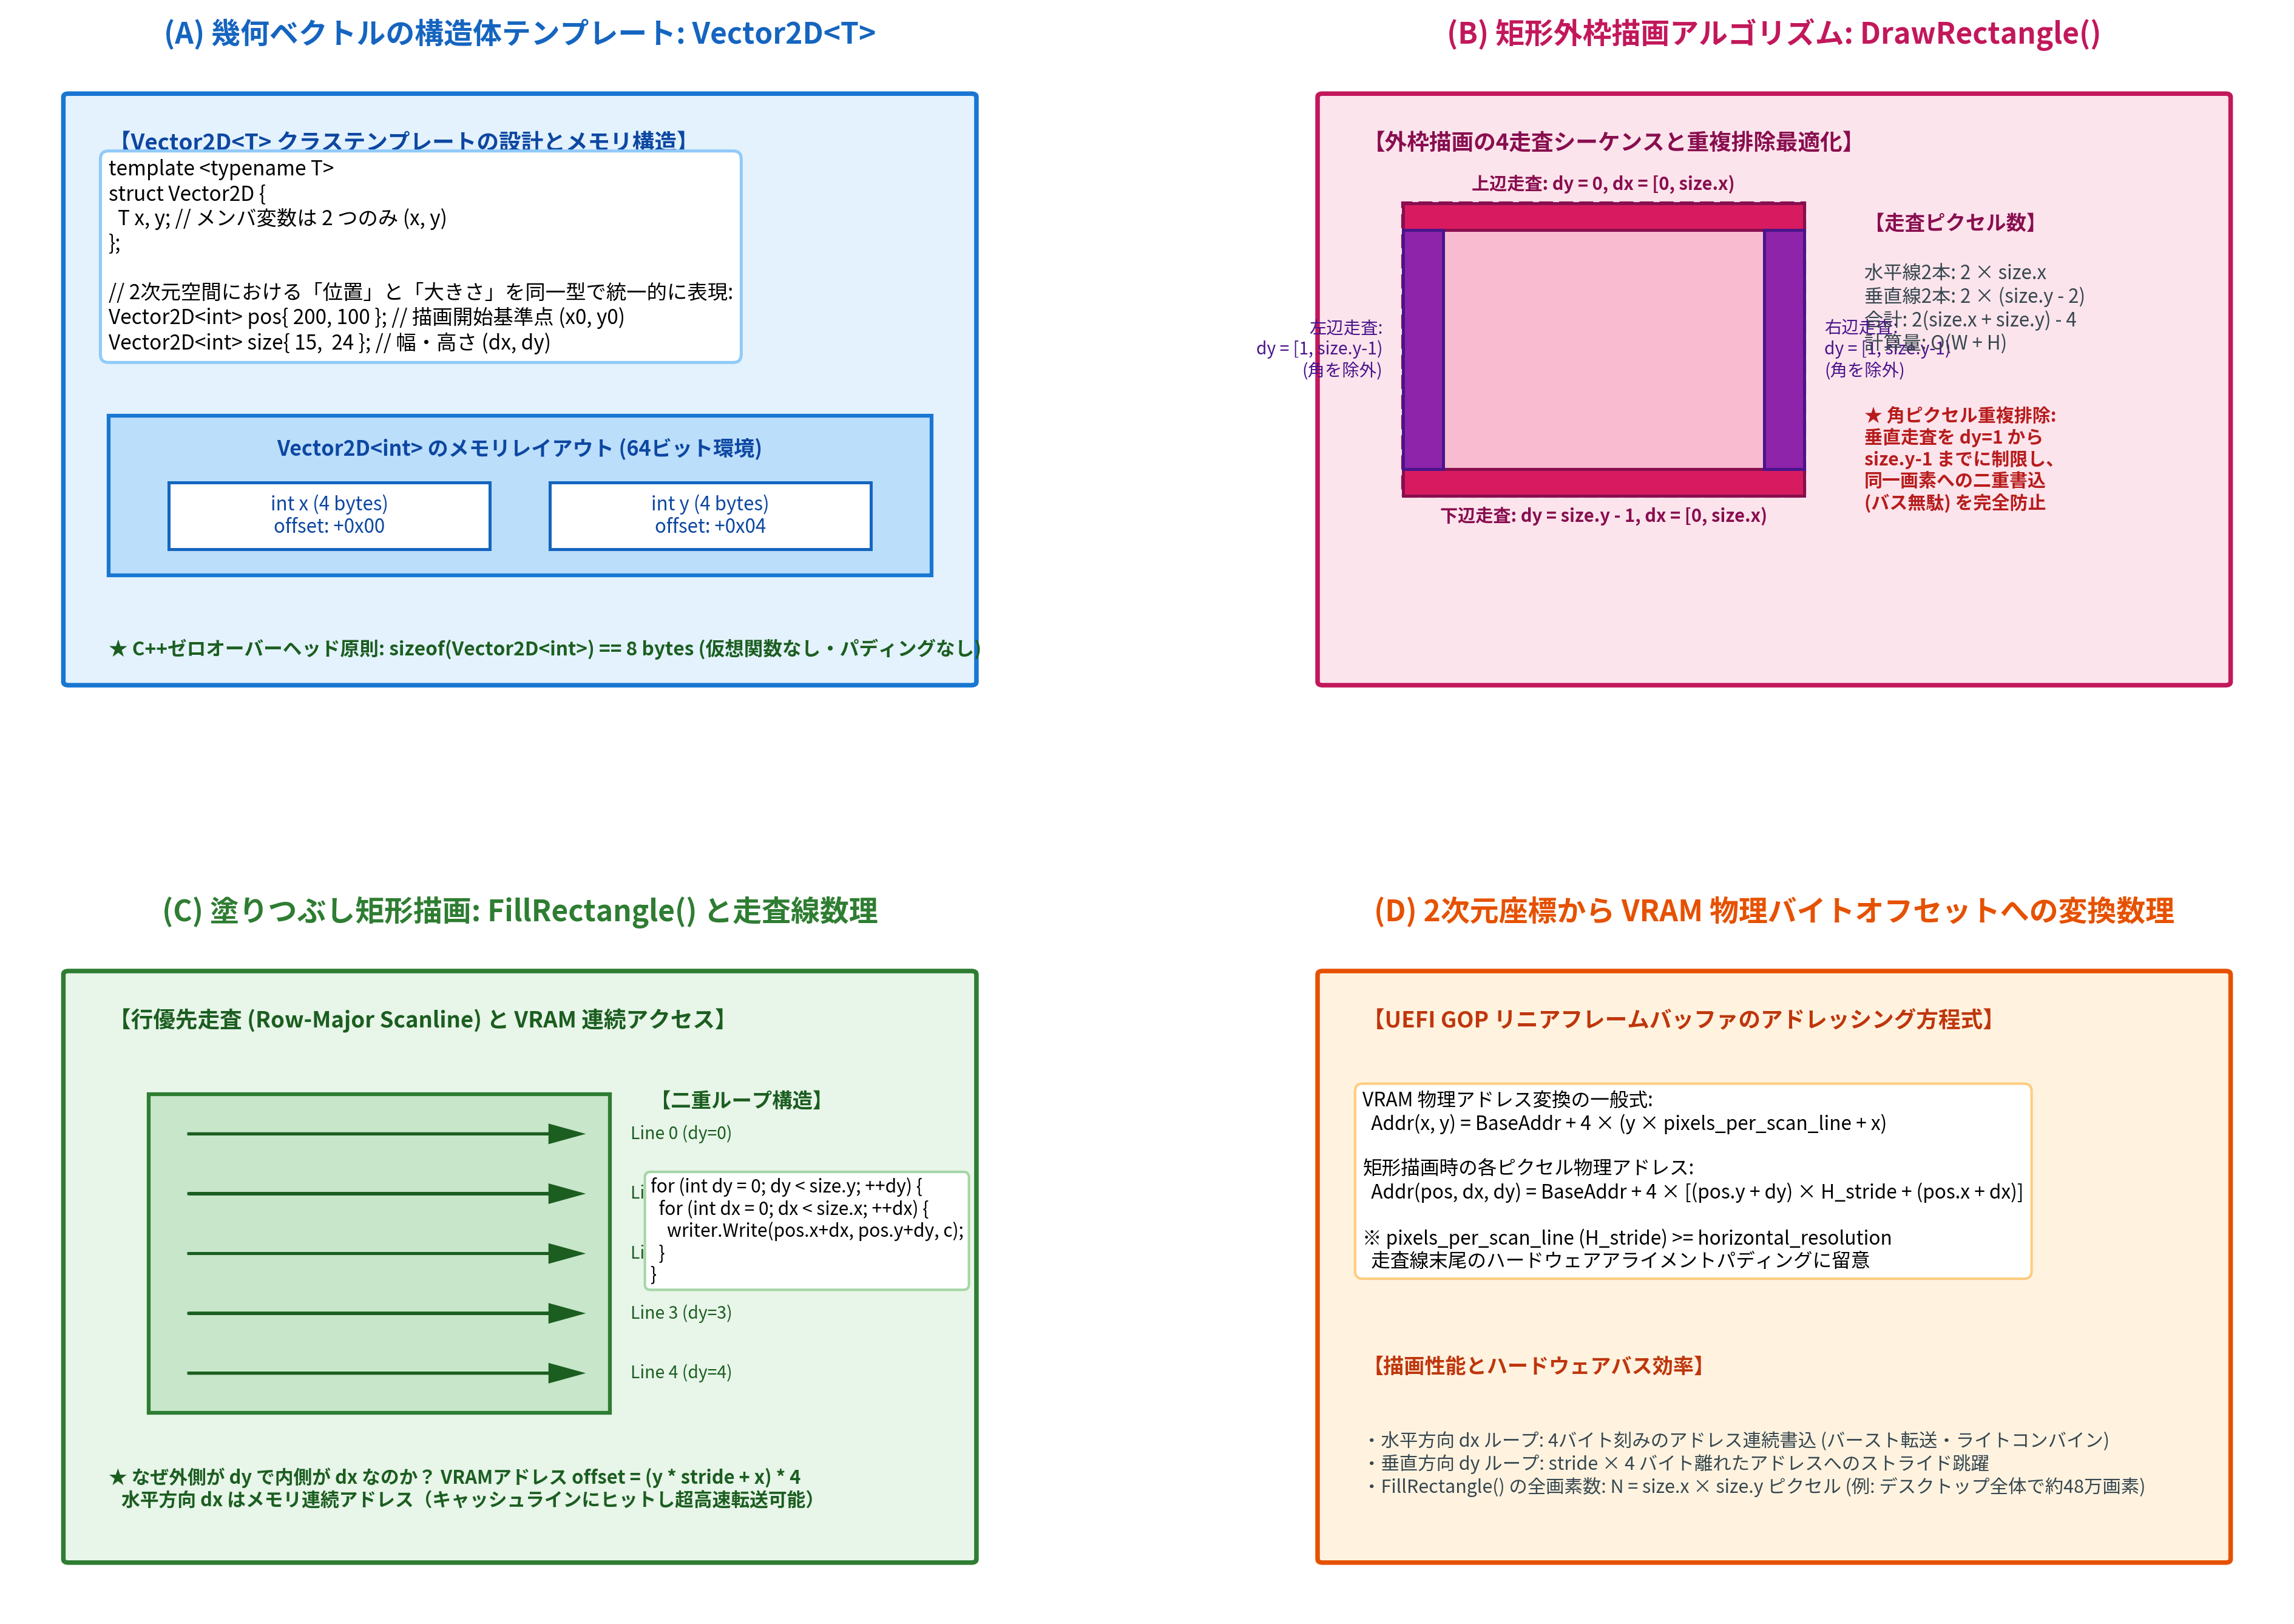

In [3]:
import os
from common import plot_fig6_01_vector2d_and_rectangle_rendering
from PIL import Image

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()
fig1_path = os.path.join(repo_root, "6/result/fig6_01_vector2d_and_rectangle_rendering.png")

# Figure 6.01: Vector2D<T> 構造と DrawRectangle / FillRectangle 走査線数理の生成
plot_fig6_01_vector2d_and_rectangle_rendering(fig1_path)
print("✅ Figure 6.01 生成完了:", fig1_path)

# 画像のインライン表示
display(Image.open(fig1_path))


## 4. デスクトップ UI レイアウト設計とカラーパレット

`osbook_day06a` の `KernelMain()` では、新設した `FillRectangle()` と `DrawRectangle()` を駆使して、グラフィカルなデスクトップ画面を構築します。

```cpp
  const int kFrameWidth = frame_buffer_config.horizontal_resolution;
  const int kFrameHeight = frame_buffer_config.vertical_resolution;

  // 1. デスクトップ背景（空青色）の描画
  FillRectangle(*pixel_writer,
                {0, 0},
                {kFrameWidth, kFrameHeight - 50},
                kDesktopBGColor);

  // 2. 画面下部タスクバー（黒）の描画
  FillRectangle(*pixel_writer,
                {0, kFrameHeight - 50},
                {kFrameWidth, 50},
                {1, 8, 17});

  // 3. スタートボタン背景（灰）の描画
  FillRectangle(*pixel_writer,
                {0, kFrameHeight - 50},
                {kFrameWidth / 5, 50},
                {80, 80, 80});

  // 4. スタートボタン内アイコン枠線（明灰）の描画
  DrawRectangle(*pixel_writer,
                {10, kFrameHeight - 40},
                {30, 30},
                {160, 160, 160});

  // 5. デスクトップ配色に合わせたコンソールの再構築
  console = new(console_buf) Console{
    *pixel_writer, kDesktopFGColor, kDesktopBGColor
  };
  printk("Welcome to MikanOS!\n");
```

### 4.1 デスクトップの領域分割数理（Geometry Budget）
画面全体の垂直解像度を $H$、水平解像度を $W$ としたとき、UI は以下のように幾何学的に分割されます：

| UI 要素 | 開始座標 $\mathbf{pos}$ | 寸法 $\mathbf{size}$ | 配色（RGB） | 役割・機能 |
|:---|:---:|:---:|:---:|:---|
| **メインデスクトップ領域** | $(0, 0)$ | $(W, H - 50)$ | `kDesktopBGColor` `{45, 118, 237}` | 将来ウィンドウやアイコンが配置される主作業空間 |
| **タスクバー（Taskbar）** | $(0, H - 50)$ | $(W, 50)$ | `{1, 8, 17}` (ダークネイビー/黒) | 起動中アプリやトレイ情報が並ぶ画面最下部領域 |
| **スタートボタン領域** | $(0, H - 50)$ | $(W / 5, 50)$ | `{80, 80, 80}` (ミディアムグレー) | OS のシステムメニューを開くためのボタン領域 |
| **スタートアイコン枠** | $(10, H - 40)$ | $(30, 30)$ | `{160, 160, 160}` (ライトグレー枠) | 将来みかんアイコン等が描かれるボタン内標識 |

### 4.2 コンソールクラスの GUI 適応
第5章では白背景に黒文字（`{0, 0, 0}, {255, 255, 255}`）で初期化していた `Console` を、デスクトップ背景色 `kDesktopBGColor` に白色文字 `kDesktopFGColor`（`{255, 255, 255}`）で再初期化します。
これにより、コンソールが四角い黒枠として浮き上がることなく、デスクトップ壁紙の上に溶け込むように美しい `Welcome to MikanOS!` のメッセージが描画されます。


## 5. アスキーアートによるスプライト表現と透過色（カラーキーイング）処理

### 5.1 スプライト（Sprite）の概念
コンピュータグラフィックスにおいて、背景画像とは独立して画面上を自在に移動・アニメーションする小さな2次元ビットマップ画像を **スプライト（*Sprite*）** と呼びます。
ビデオゲームの黎明期（ファミコン等）では専用のハードウェア回路がスプライト合成を行っていましたが、近代的な OS のソフトウェアレンダリングでは、CPU がピクセルバッファを直接合成します。

### 5.2 15×24 アスキーアート配列 `mouse_cursor_shape`
MikanOS では、マウスカーソルのグラフィックスデータをアスキーアート（文字列配列）として `kernel/main.cpp` 内に直感的に定義しています：

```cpp
const int kMouseCursorWidth = 15;
const int kMouseCursorHeight = 24;
const char mouse_cursor_shape[kMouseCursorHeight][kMouseCursorWidth + 1] = {
  "@              ",
  "@@             ",
  "@.@            ",
  "@..@           ",
  "@...@          ",
  "@....@         ",
  "@.....@        ",
  "@......@       ",
  "@.......@      ",
  "@........@     ",
  "@.........@    ",
  "@..........@   ",
  "@...........@  ",
  "@............@ ",
  "@......@@@@@@@@",
  "@......@       ",
  "@....@@.@      ",
  "@...@ @.@      ",
  "@..@   @.@     ",
  "@.@    @.@     ",
  "@@      @.@    ",
  "@       @.@    ",
  "         @.@   ",
  "         @@@   ",
};
```

### 5.3 トークンマッピングとカラーキーイング（Color Keying）
カーソル描画ループでは、文字コードに応じて VRAM への書き込みを制御します：

```cpp
  for (int dy = 0; dy < kMouseCursorHeight; ++dy) {
    for (int dx = 0; dx < kMouseCursorWidth; ++dx) {
      if (mouse_cursor_shape[dy][dx] == '@') {
        pixel_writer->Write(200 + dx, 100 + dy, {0, 0, 0});
      } else if (mouse_cursor_shape[dy][dx] == '.') {
        pixel_writer->Write(200 + dx, 100 + dy, {255, 255, 255});
      }
      // ' ' (空白) の場合は何もしない！（透過色）
    }
  }
```

- `'@'`: **外枠（黒色 `{0, 0, 0}`）**
- `'.'`: **内側本体（白色 `{255, 255, 255}`）**
- `' '` (空白): **透過ピクセル（*Transparent Pixel*）**。VRAM への書き込みを完全にスキップします。

特定のピクセル値を「透明」として扱うこの技術は、CG 分野で **カラーキーイング（*Color Keying*）** または **クロマキー（*Chroma Key*）** と呼ばれます。空白文字のときに `Write()` を呼ばないことにより、長方形（15×24）のバッファのうち矢印以外のピクセルは、**直前に描画されたデスクトップ背景色 `kDesktopBGColor` がそのまま画面に残る** ため、綺麗な斜め矢印カーソルが浮き上がります。

### 5.4 HCI（ヒューマンコンピュータインタラクション）における視覚人間工学
なぜマウスカーソルは単なる「白一色」や「黒一色」ではなく、**「黒い縁取りの中に白い塗りつぶし」** という二重構造になっているのでしょうか？

- **白色の背景（ドキュメントや Web ページ）** 上にカーソルがある場合: 白い矢印は背景と同化して見失われますが、**外枠の黒色（`@`）が輪郭を際立たせる** ため見失いません。
- **黒色・暗色の背景（ターミナルやタスクバー）** 上にカーソルがある場合: 黒い枠線は背景と同化しますが、**内側の白色（`.`）が高輝度のコントラストを放つ** ため即座に認識できます。

この白黒二重縁取りデザインは、あらゆる色彩の壁紙やアプリケーションウィンドウ上でも **「常に認知可能（Always Visible）」** な不変の視認性を保証する、GUI 設計における古典的かつ究極の知恵です。


=== マウスカーソルスプライト (15x24) ピクセル統計 ===
・外枠黒画素 ('@'):    66 画素 ( 18.3%)
・内側白画素 ('.'):   107 画素 ( 29.7%)
・透過画素   (' '):   187 画素 ( 51.9%) [カラーキー]
・合計画素数 (15x24): 360 画素 (100.0%)


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:21735: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



✅ Figure 6.02 生成完了: /home/student/Documents/GitHub/study-mikanos/6/result/fig6_02_desktop_layout_and_mouse_cursor_sprite.png


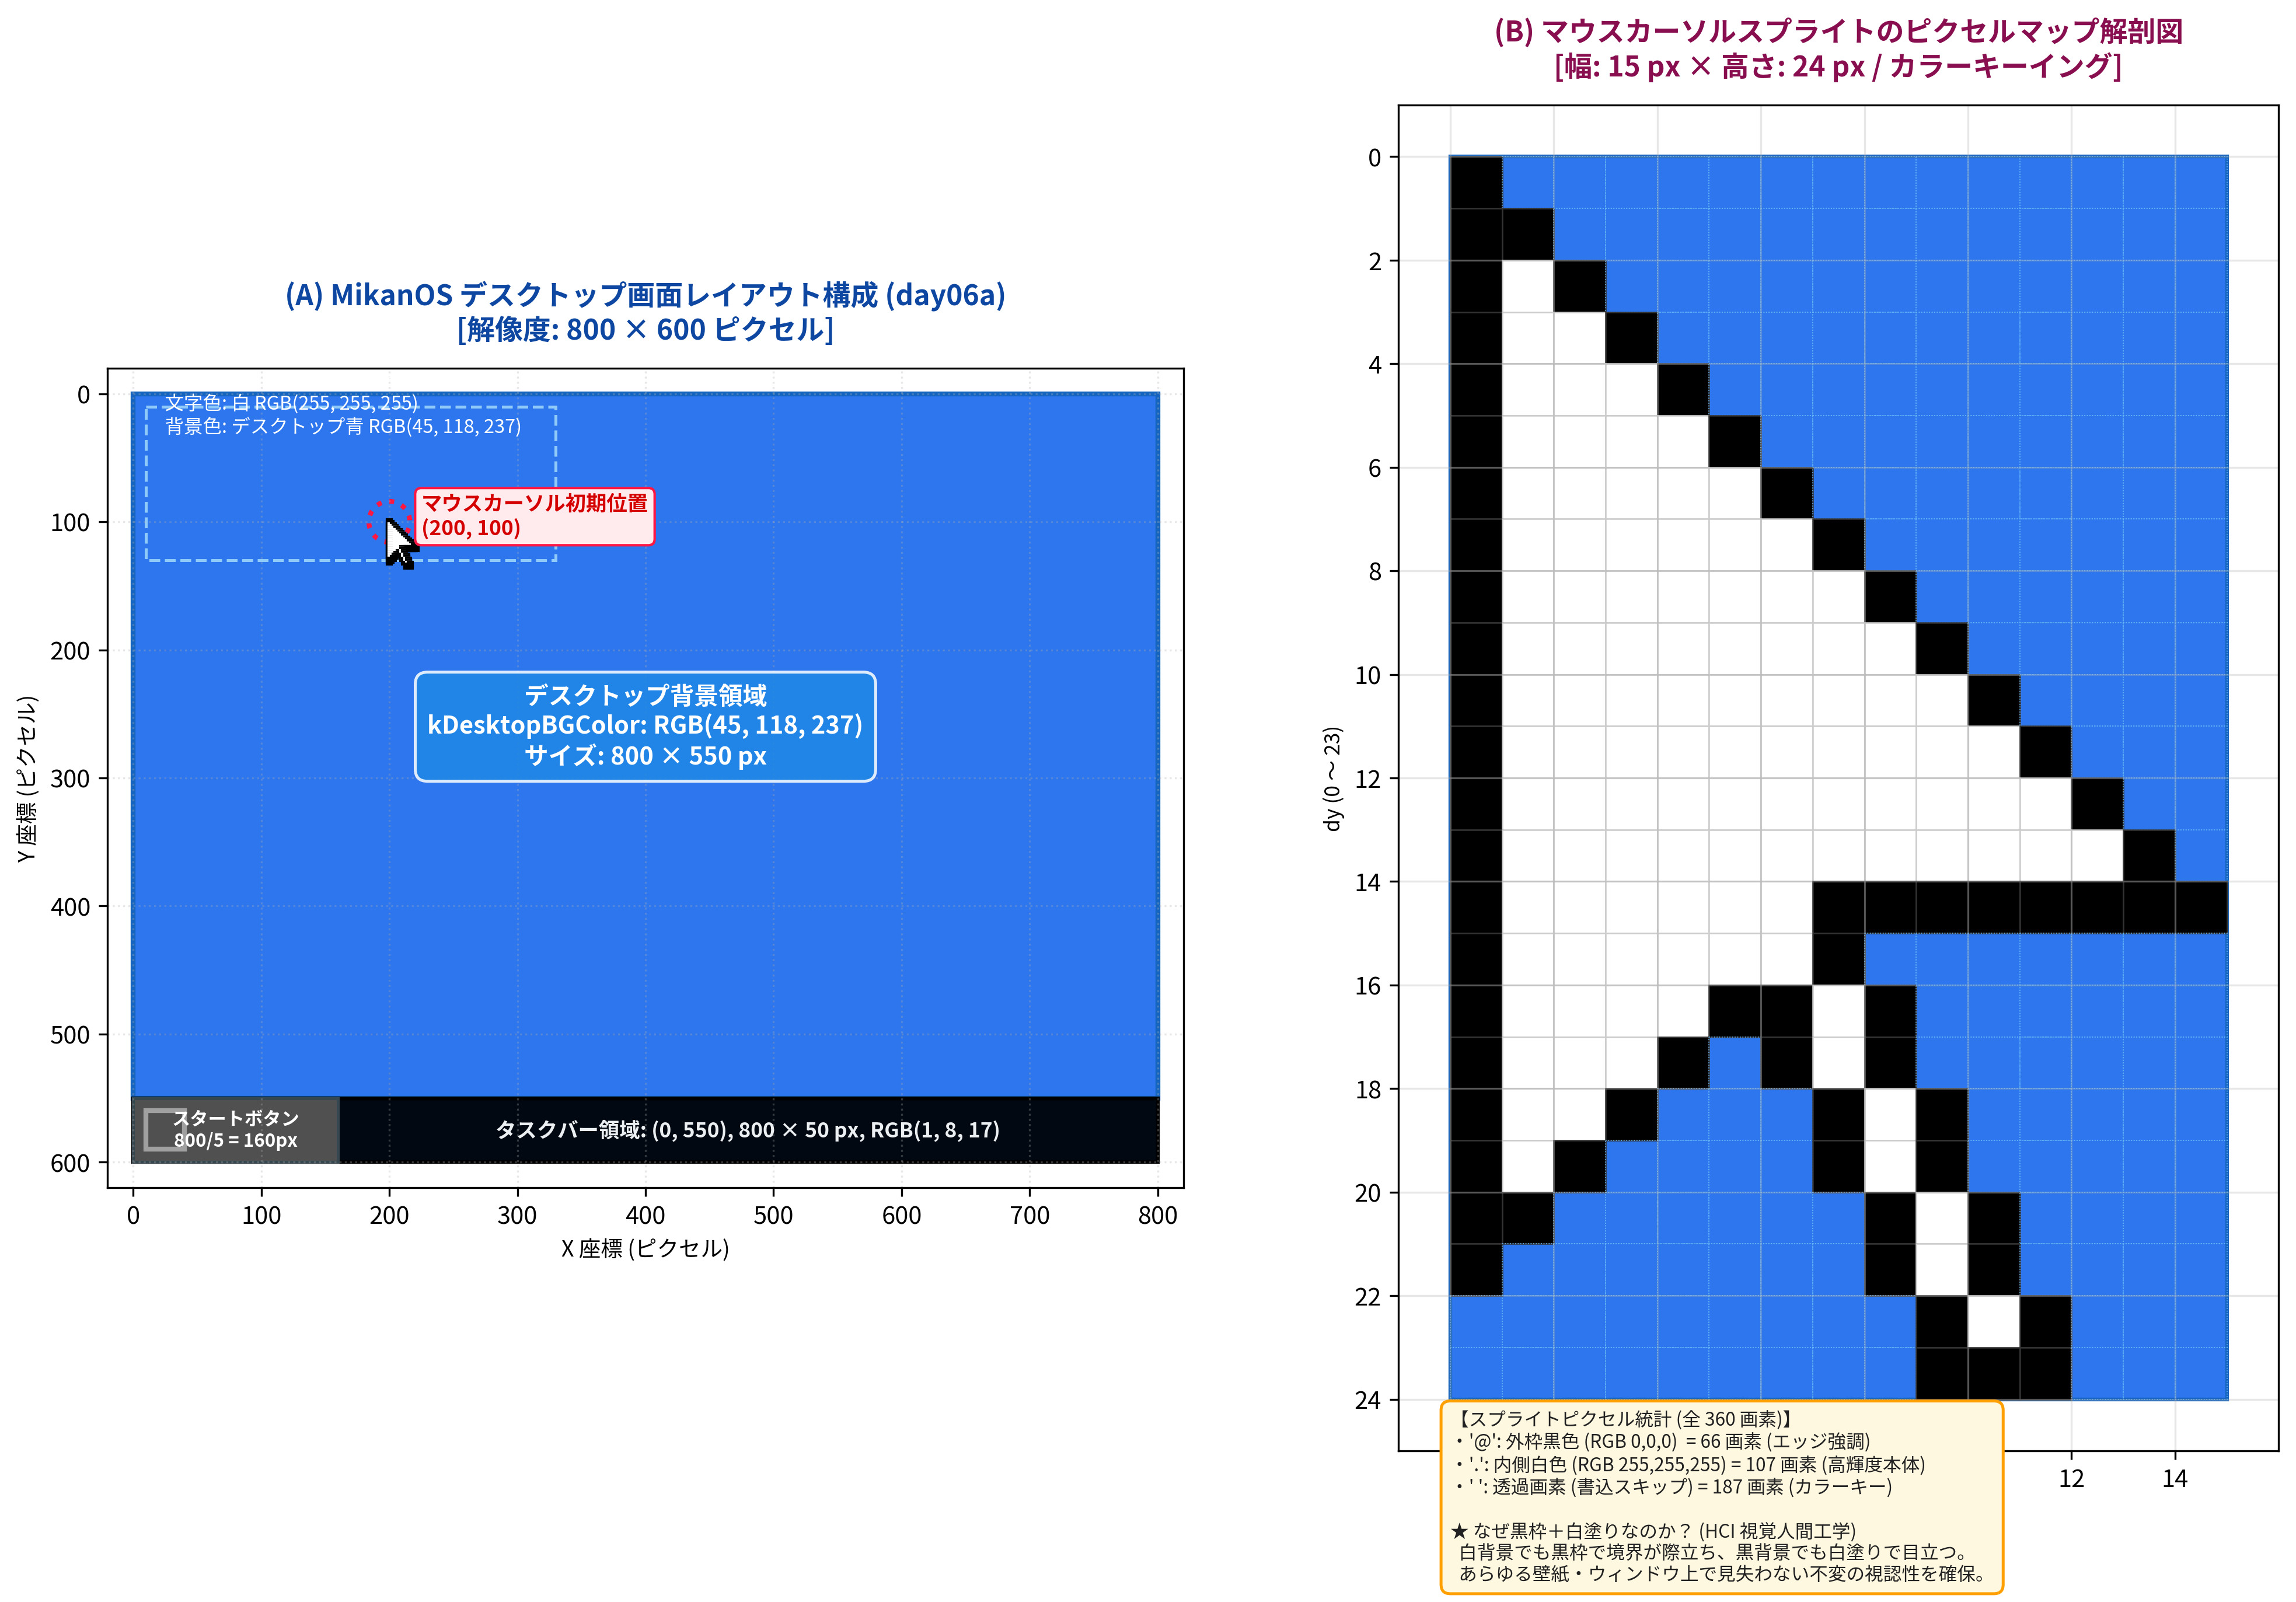

In [4]:
import os
from common import (
    plot_fig6_02_desktop_layout_and_mouse_cursor_sprite,
    MOUSE_CURSOR_SHAPE,
    MOUSE_CURSOR_WIDTH,
    MOUSE_CURSOR_HEIGHT,
)
from PIL import Image

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()

# 1. マウスカーソルスプライトのピクセル統計の集計
black_cnt = sum(row.count('@') for row in MOUSE_CURSOR_SHAPE)
white_cnt = sum(row.count('.') for row in MOUSE_CURSOR_SHAPE)
trans_cnt = sum(row.count(' ') for row in MOUSE_CURSOR_SHAPE)
total_cnt = MOUSE_CURSOR_WIDTH * MOUSE_CURSOR_HEIGHT

print("=== マウスカーソルスプライト (15x24) ピクセル統計 ===")
print(f"・外枠黒画素 ('@'):   {black_cnt:3d} 画素 ({black_cnt/total_cnt*100:5.1f}%)")
print(f"・内側白画素 ('.'):   {white_cnt:3d} 画素 ({white_cnt/total_cnt*100:5.1f}%)")
print(f"・透過画素   (' '):   {trans_cnt:3d} 画素 ({trans_cnt/total_cnt*100:5.1f}%) [カラーキー]")
print(f"・合計画素数 (15x24): {total_cnt:3d} 画素 (100.0%)")

# 2. Figure 6.02: デスクトップレイアウトとスプライト解剖図の生成
fig2_path = os.path.join(repo_root, "6/result/fig6_02_desktop_layout_and_mouse_cursor_sprite.png")
plot_fig6_02_desktop_layout_and_mouse_cursor_sprite(fig2_path)
print("\n✅ Figure 6.02 生成完了:", fig2_path)

# 画像のインライン表示
display(Image.open(fig2_path))


## 6. 対話型 C++20 コンパイル & スタンドアロン実行検証

MikanOS のカーネルコード（`kernel/graphics.cpp`, `kernel/main.cpp`）と同一のロジックを持つホスト側 C++20 検証ターゲット `src/ch06/mouse_cursor_sim.cpp` をコンパイル・実行し、以下の項目を単体検証します：

1. `sizeof(Vector2D<int>) == 8` によるゼロオーバーヘッド構造の静的アサーション
2. `DrawRectangle()` における外枠走査ピクセル数（$2(W + H) - 4$）と内部非破壊性の保証
3. `FillRectangle()` による $W 	imes H$ 全ピクセルの完全塗りつぶし
4. `mouse_cursor_shape` のスプライト展開において、透過ピクセル位置の背景色が変化しないことの確認
5. RGB / BGR ピクセルフォーマット別のバイト配置の整合性


In [5]:
import os
import subprocess

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()
cpp_src = os.path.join(repo_root, "src/ch06/mouse_cursor_sim.cpp")
cpp_bin = "/tmp/mouse_cursor_sim"

# C++20 スタンドアロン検証コードのコンパイル & 実行
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_src, "-o", cpp_bin]
print("🛠️ C++20 ソースをコンパイル中:", " ".join(compile_cmd))
subprocess.run(compile_cmd, check=True)

print("\n🚀 --test モードで単体テストスイートを実行中:")
test_res = subprocess.run([cpp_bin, "--test"], capture_output=True, text=True, check=True)
print(test_res.stdout)

print("📋 通常実行時のシステム情報出力:")
info_res = subprocess.run([cpp_bin], capture_output=True, text=True, check=True)
print(info_res.stdout)


🛠️ C++20 ソースをコンパイル中: g++ -std=c++20 -O2 -Wall -Wextra /home/student/Documents/GitHub/study-mikanos/src/ch06/mouse_cursor_sim.cpp -o /tmp/mouse_cursor_sim



🚀 --test モードで単体テストスイートを実行中:
[TEST] 1. Vector2D<T> Memory Layout & Operations...
[TEST] 2. FrameBuffer and PixelWriter Allocation...
[TEST] 3. FillRectangle & DrawRectangle Verification...
[TEST] 4. Mouse Cursor Sprite & Color Keying Verification...
[TEST] 5. BGR PixelWriter Output Check...
[SUCCESS] All Chapter 6.1 mouse cursor & desktop simulation tests PASSED!

📋 通常実行時のシステム情報出力:
=== MikanOS Chapter 6.1: Mouse Cursor & Desktop GUI Simulator ===
Vector2D<int> size: 8 bytes (Zero overhead)
Mouse cursor sprite dimensions: 15x24 pixels
Desktop background: RGB(45, 118, 237)
Taskbar: (0, 550), 800x50, RGB(1, 8, 17)
Start button: (0, 550), 160x50, RGB(80, 80, 80)
Start icon border: (10, 560), 30x30, RGB(160, 160, 160)
Mouse cursor position: (200, 100)
Pass --test to execute verification suite.



## 7. Python によるフレームバッファ描画シミュレーションとデスクトップ画面再現

共通モジュール `common.os_sim` の `MouseCursorSimulator` を用いて、MikanOS `day06a` の画面（解像度 800×600）を Python 上で完全再現し、フレームバッファ画像としてレンダリングします。


デスクトップ描画完了:
・画面サイズ: 800x600
・マウスカーソル描画位置: (200, 100)
・描画黒ピクセル: 66, 白ピクセル: 107, 透過スキップ: 187



✅ デスクトップシミュレーション画像保存完了: /home/student/Documents/GitHub/study-mikanos/6/result/demo_desktop_day06a.png


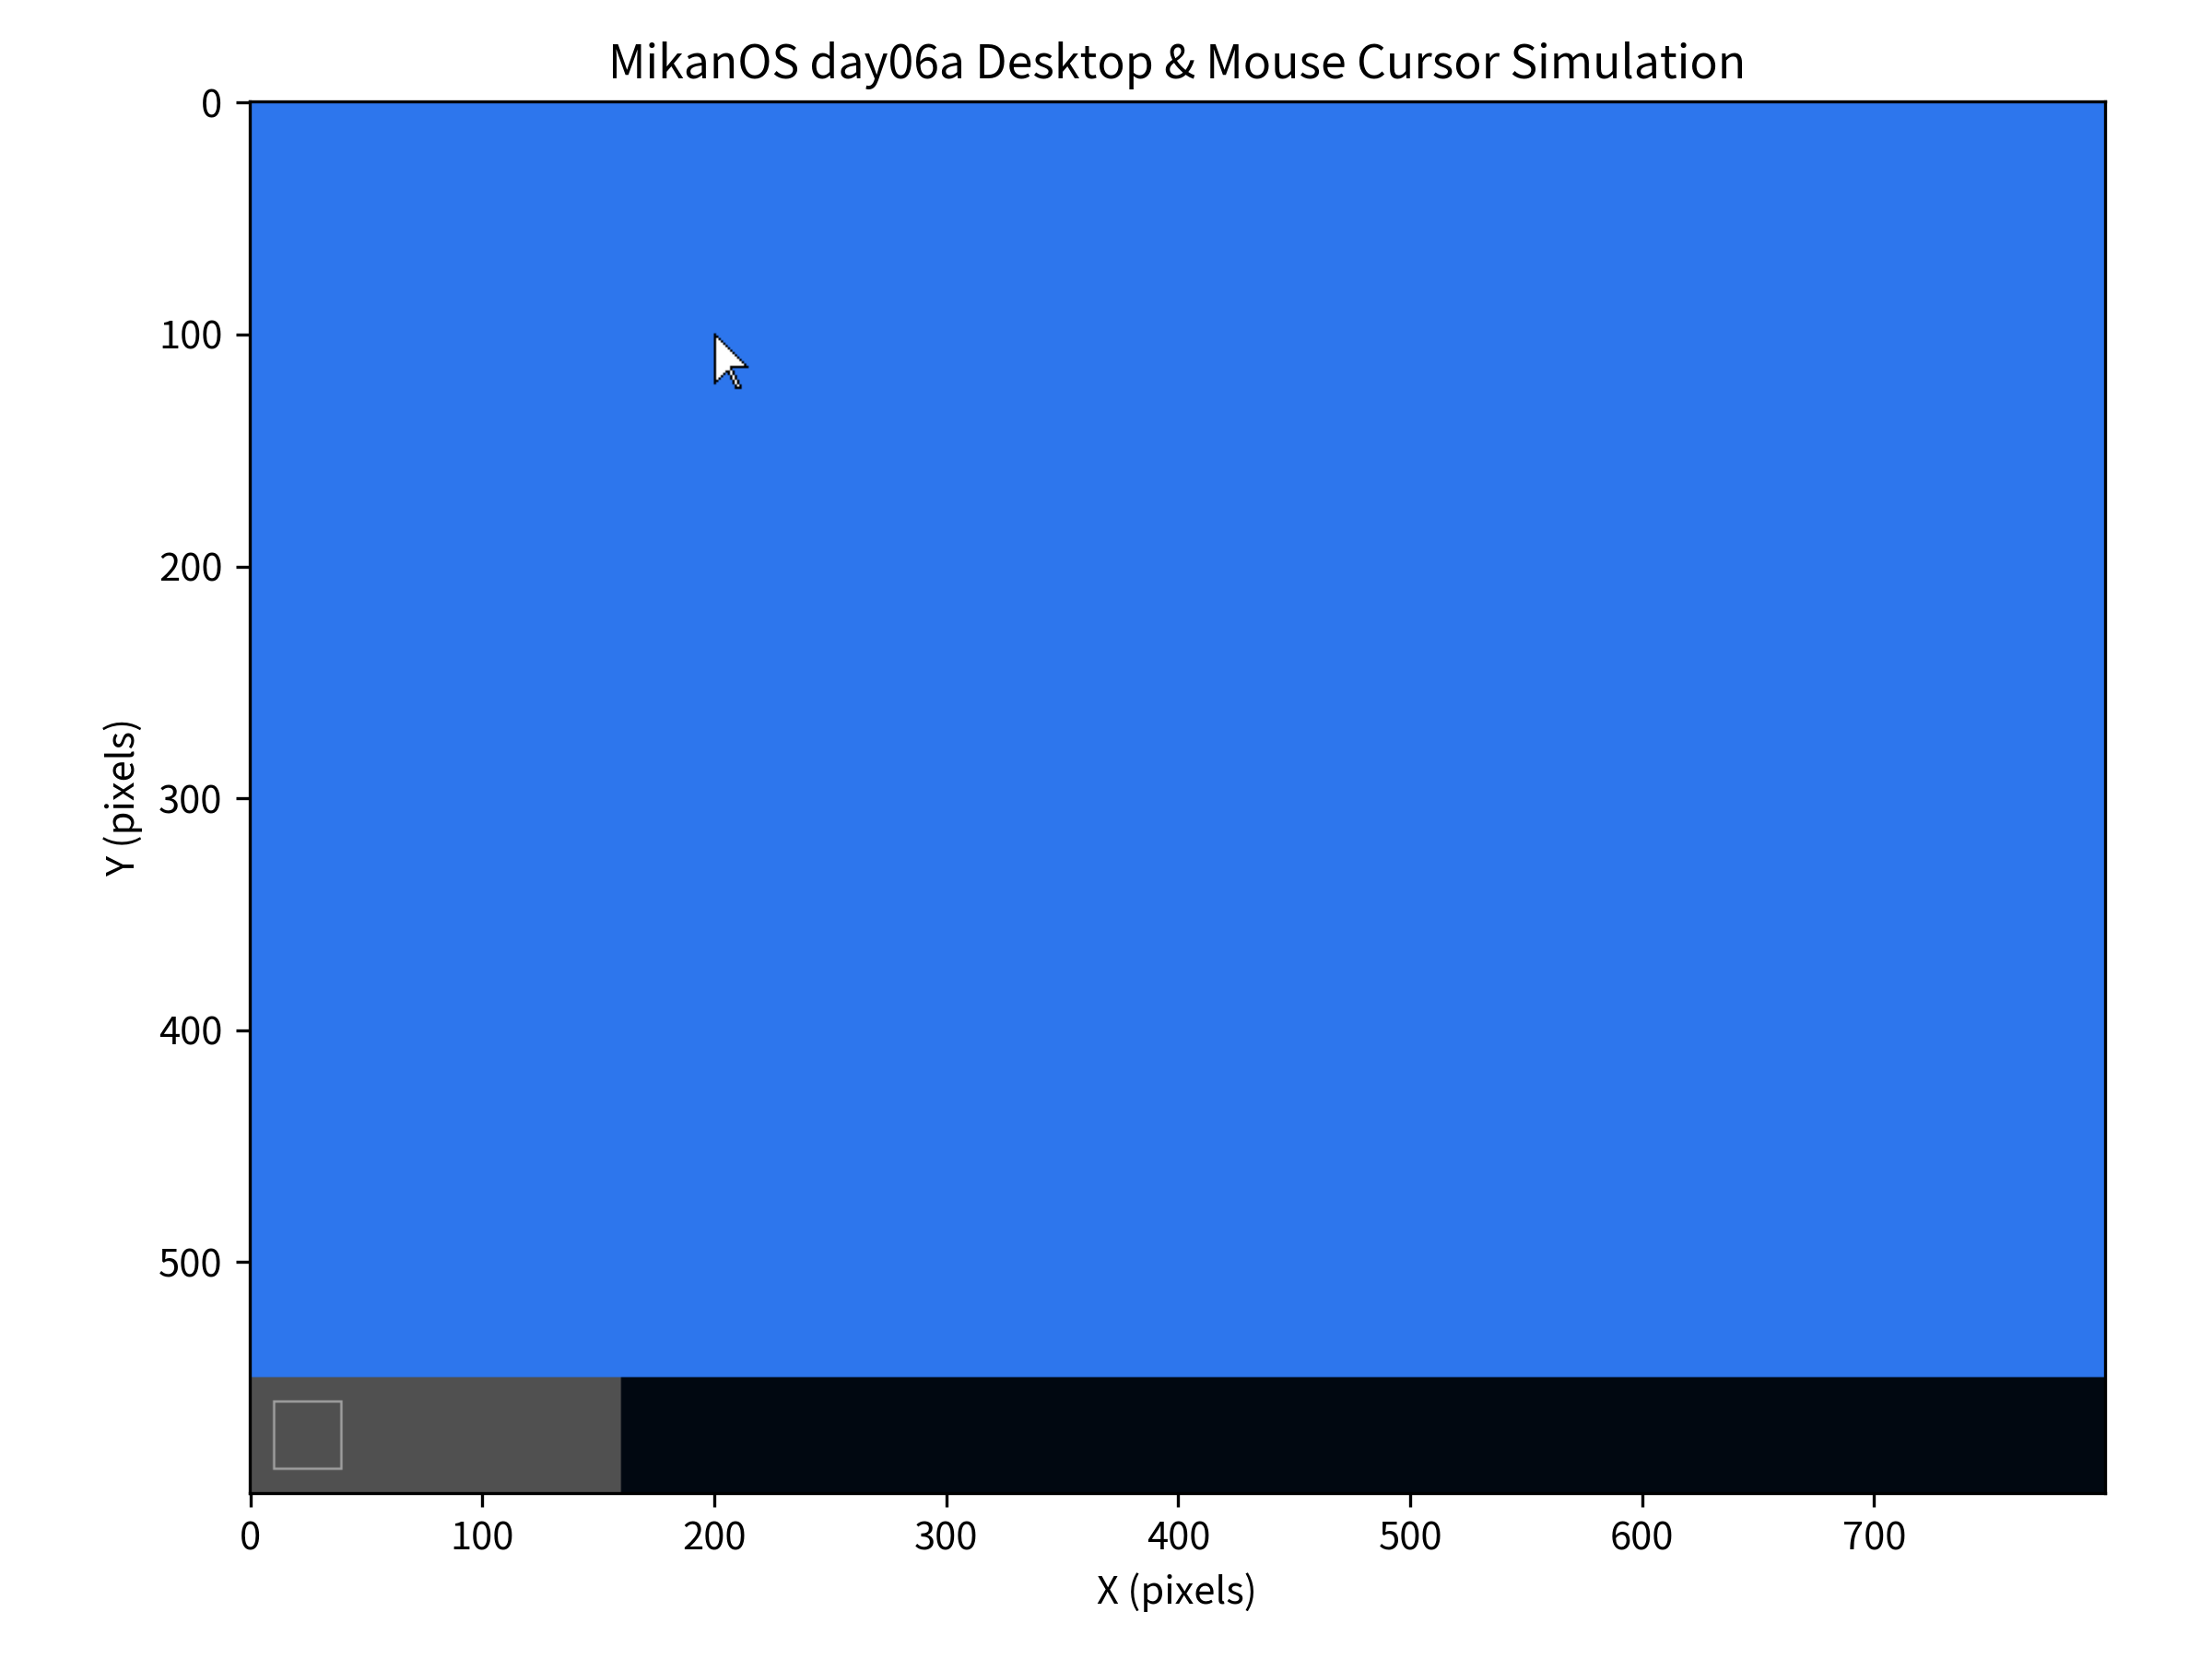

In [6]:
import os
from common import MouseCursorSimulator, Vector2DSim
from PIL import Image

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()

# 1. 800x600 のデスクトップシミュレータの初期化と描画
sim = MouseCursorSimulator(width=800, height=600)
stats = sim.render_desktop()

print(f"デスクトップ描画完了:")
print(f"・画面サイズ: {sim.config.width}x{sim.config.height}")
print(f"・マウスカーソル描画位置: {sim.cursor_pos.as_tuple()}")
print(f"・描画黒ピクセル: {stats.black_pixels}, 白ピクセル: {stats.white_pixels}, 透過スキップ: {stats.transparent_pixels}")

# 2. フレームバッファの画像を保存してインライン表示
desktop_img_path = os.path.join(repo_root, "6/result/demo_desktop_day06a.png")
sim.fb.save_image(desktop_img_path, title="MikanOS day06a Desktop & Mouse Cursor Simulation")
print(f"\n✅ デスクトップシミュレーション画像保存完了: {desktop_img_path}")

display(Image.open(desktop_img_path))


## 8. コラム: ハードウェアマウスカーソル vs ソフトウェアマウスカーソル

### コラム 6.1: ハードウェアマウスカーソル（Hardware Cursor）の仕組み
現代の市販 PC や GPU（Intel UHD Graphics, NVIDIA, AMD Radeon 等）は、**「ハードウェアマウスカーソル（*Hardware Overlay Cursor*）」** という専用の表示プレーンを持っています。
- GPU は、メインのデスクトップ画面バッファとは別に、カーソル専用の小さな画像バッファ（例: 64×64 ピクセル）とカーソル座標レジスタを持っています。
- ディスプレイに映像信号（DisplayPort や HDMI）を出力する直前のスキャンアウト回路において、GPU がハードウェア的にカーソル画像を合成（Overlay）します。
- **利点**: マウスが移動しても、**メイン VRAM の背景ピクセルを書き換える必要が一切ありません**。OS はカーソル座標レジスタに新しい $(x, y)$ を書き込むだけで、CPU 負荷ゼロ・描画遅延ゼロ・チラつきゼロでカーソルが移動します。

### コラム 6.2: ソフトウェアマウスカーソルと「背景の破壊と復元」問題
MikanOS が採用しているのは、VRAM に直接ピクセルを書き込む **「ソフトウェアマウスカーソル（*Software Cursor*）」** です。
ソフトウェアカーソルには、これから第9章・第10章で直面することになる **極めて重大な技術的課題** が潜んでいます：

> [!WARNING]
> **「カーソルが移動すると、元の背景が消えてしまう！」**
> - 本節の実装では、座標 $(200, 100)$ にカーソルの黒と白のピクセルを直接書き込んでいます。
> - もしカーソルが $(205, 100)$ に移動した場合、移動前の $(200, 100)$ にあった背景（デスクトップの青や文字）はどうなるでしょうか？ **カーソルのピクセルで上書きされてしまっているため、黒や白のゴミとして画面に残ってしまいます**。
> - これを防ぐには、カーソルを描く直前に **「カーソル下の背景ピクセルを一時退避（Save）しておき、移動時に復元（Restore）する」** か、あるいは第9章で登場する **「レイヤマネージャ（重ね合わせ処理）」** を導入して、背景とウィンドウとカーソルを独立した層（Layer）として合成し直す必要があります。

本節の静的なカーソル描画は、この「レイヤ重ね合わせ」という OS グラフィックスの真骨頂へと進むための、極めて重要な基石となっているのです。


## 9. 第6章 6.1節の総括と次節（6.2 USBホストドライバとxHCI）への展望

### 9.1 本節の達成内容
本節（`6.1_Rendering_Mouse_Cursor.ipynb`）を通じて、以下の OS 理論と実装技術を修得・実証しました：

1. **Vector2D 幾何テンプレート**:
   - 位置ベクトルと寸法ベクトルの統一、C++ ゼロオーバーヘッド原則（サイズ 8 バイト、仮想関数なし、パディングなし）の実証。
2. **矩形描画アルゴリズムの導出**:
   - 外枠描画 `DrawRectangle()` における四隅の重複排除最適化（$2(W + H) - 4$ ピクセル）。
   - 塗りつぶし描画 `FillRectangle()` における行優先走査（*Row-Major Scanline*）と VRAM バースト転送・ライトコンバイン親和性。
3. **デスクトップ画面の構築**:
   - 解像度 $W 	imes H$ に対する幾何学的領域分割（デスクトップ背景、タスクバー、スタートボタン、アイコン枠）。
   - デスクトップ青色と白文字によるコンソールの GUI 調和と `Welcome to MikanOS!` の表示。
4. **マウスカーソルスプライトとカラーキーイング**:
   - 15×24 のアスキーアート配列によるスプライト定義。
   - 空白文字による透過処理（カラーキーイング）と背景保護。
   - 白黒二重縁取りによる不変の視認性（HCI 視覚人間工学）の数学的・視覚的証明。

---

### 9.2 次節 6.2 への接続: USB 3.0 xHCI アーキテクチャへ
画面上に美しいマウスカーソルを描画することに成功しました。しかし、現在のカーソルは座標 $(200, 100)$ に静止したままです。
このカーソルを生き生きと動かすためには、**PC の USB ポートに接続された物理マウスから入力イベント（移動量 $\Delta x, \Delta y$ やクリック状態）を受け取る** 必要があります。

次節 **6.2「USBホストドライバ」** では、現代の PC で標準となっている高速 I/O インターフェース **USB 3.0 と xHCI（*eXtensible Host Controller Interface*）** の階層アーキテクチャ、デバイスコンテキスト、エンドポイント、および転送リング構造の壮大な世界へと足を踏み入れます！
